In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [12]:
df = pd.read_csv(
    "dataset/raw/hospital_waiting_time.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


/var/folders/29/k6fd864d6wn_jmnqfhhschwh0000gn/T/ipykernel_6793/3091142672.py:1: DtypeWarning: Columns (253: HDDIAG5, 646: DRUGID18, 666: DRUGID19, 686: DRUGID20, 706: DRUGID21, 726: DRUGID22, 746: DRUGID23, 766: DRUGID24, 786: DRUGID25, 806: DRUGID26, 826: DRUGID27, 846: DRUGID28, 866: DRUGID29, 886: DRUGID30) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


In [13]:
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (16025, 913)


,VMONTH,VDAYR,ARRTIME,WAITTIME,LOV,AGE,AGER,AGEDAYS,RESIDNCE,SEX,...,RX30V3C2,RX30V3C3,RX30V3C4,SETTYPE,YEAR,CSTRATM,CPSUM,PATWT,EDWT,BOARDED
0,9,2,604,10,228,23,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,8.36413,-7
1,9,2,1053,40,319,15,2,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
2,9,2,1419,70,551,19,2,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
3,9,2,1825,-7,-9,0,1,298,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
4,9,2,2243,14,168,18,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7


In [14]:
df.shape

(16025, 913)

In [15]:
df.head()

,VMONTH,VDAYR,ARRTIME,WAITTIME,LOV,AGE,AGER,AGEDAYS,RESIDNCE,SEX,...,RX30V3C2,RX30V3C3,RX30V3C4,SETTYPE,YEAR,CSTRATM,CPSUM,PATWT,EDWT,BOARDED
0,9,2,604,10,228,23,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,8.36413,-7
1,9,2,1053,40,319,15,2,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
2,9,2,1419,70,551,19,2,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
3,9,2,1825,-7,-9,0,1,298,1,2,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
4,9,2,2243,14,168,18,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7


In [17]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 16025
Total Columns: 913


In [18]:
for i, col in enumerate(df.columns):
    print(i + 1, col)

1 VMONTH
2 VDAYR
3 ARRTIME
4 WAITTIME
5 LOV
6 AGE
7 AGER
8 AGEDAYS
9 RESIDNCE
10 SEX
11 ETHUN
12 ETHIM
13 RACEUN
14 RACER
15 RACERETH
16 ARREMS
17 AMBTRANSFER
18 NOPAY
19 PAYPRIV
20 PAYMCARE
21 PAYMCAID
22 PAYWKCMP
23 PAYSELF
24 PAYNOCHG
25 PAYOTH
26 PAYDK
27 PAYTYPER
28 TEMPF
29 PULSE
30 RESPR
31 BPSYS
32 BPDIAS
33 POPCT
34 IMMEDR
35 PAINSCALE
36 SEEN72
37 RFV1
38 RFV2
39 RFV3
40 RFV4
41 RFV5
42 RFV13D
43 RFV23D
44 RFV33D
45 RFV43D
46 RFV53D
47 EPISODE
48 INJURY
49 INJPOISAD
50 INJURY72
51 INTENT15
52 INJURY_ENC
53 CAUSE1
54 CAUSE2
55 CAUSE3
56 DIAG1
57 DIAG2
58 DIAG3
59 DIAG4
60 DIAG5
61 PRDIAG1
62 PRDIAG2
63 PRDIAG3
64 PRDIAG4
65 PRDIAG5
66 ETOHAB
67 ALZHD
68 ASTHMA
69 CANCER
70 CEBVD
71 CKD
72 COPD
73 CHF
74 CAD
75 DEPRN
76 DIABTYP1
77 DIABTYP2
78 DIABTYP0
79 ESRD
80 HPE
81 EDHIV
82 HYPLIPID
83 HTN
84 OBESITY
85 OSA
86 OSTPRSIS
87 SUBSTAB
88 NOCHRON
89 TOTCHRON
90 DIAGSCRN
91 ABG
92 BAC
93 BMP
94 BNP
95 BUNCREAT
96 CARDENZ
97 CBC
98 CMP
99 BLOODCX
100 TRTCX
101 URINECX
102 WOUNDCX


In [19]:
# Search for waiting-time related columns
for col in df.columns:
    if any(word in col.upper() for word in
           ["WAIT", "ARR", "TIME", "BOARD", "TRIAGE"]):
        print(col)

ARRTIME
WAITTIME
ARREMS
BOARD
BOARDHOS
CATRIAGE
BOARDED


In [20]:
if "WAITTIME" in df.columns:
    print("WAITTIME column found!")
    print(df["WAITTIME"].describe())
else:
    print("WAITTIME column not found!")

WAITTIME column found!
count    16025.000000
mean        28.363557
std         61.939166
min         -9.000000
25%          1.000000
50%         10.000000
75%         31.000000
max       1280.000000
Name: WAITTIME, dtype: float64


In [21]:
df.isnull().sum().sort_values(
    ascending=False
).head(20)

RX19V3C4    16025
RX25V3C4    16025
RX18V3C4    16025
RX28V1C3    16025
RX28V1C4    16025
RX18V2C4    16025
RX28V2C3    16025
RX28V2C4    16025
RX18V1C4    16025
RX28V3C3    16025
RX28CAT3    16025
RX28V3C4    16025
RX23V3C4    16025
RX18CAT4    16025
RX25V3C3    16025
RX16CAT4    16025
RX26V3C4    16025
RX29CAT2    16025
RX28CAT4    16025
RX19CAT4    16025
dtype: int64

In [22]:
print("Blank values (-9):",
      (df["WAITTIME"] == -9).sum())

print("Not applicable values (-7):",
      (df["WAITTIME"] == -7).sum())

print("Valid waiting times:",
      df["WAITTIME"].between(0, 1280).sum())

Blank values (-9): 2173
Not applicable values (-7): 580
Valid waiting times: 13272


In [23]:
# Remove invalid waiting-time records

df_clean = df[
    df["WAITTIME"].between(0, 1280)
].copy()

print("Original dataset shape:", df.shape)

print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (16025, 913)
Cleaned dataset shape: (13272, 913)


In [24]:
print("Cleaned Waiting Time Statistics")

print(df_clean["WAITTIME"].describe())

Cleaned Waiting Time Statistics
count    13272.000000
mean        36.026447
std         65.500736
min          0.000000
25%          5.000000
50%         14.000000
75%         39.000000
max       1280.000000
Name: WAITTIME, dtype: float64


In [25]:
import os

os.makedirs("../dataset/processed", exist_ok=True)

In [26]:
df_clean.to_csv(
    "../dataset/processed/cleaned_hospital_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
import os

print(os.path.exists(
    "../dataset/processed/cleaned_hospital_data.csv"
))


True


In [28]:
df_clean["WAITTIME"].describe()

count    13272.000000
mean        36.026447
std         65.500736
min          0.000000
25%          5.000000
50%         14.000000
75%         39.000000
max       1280.000000
Name: WAITTIME, dtype: float64

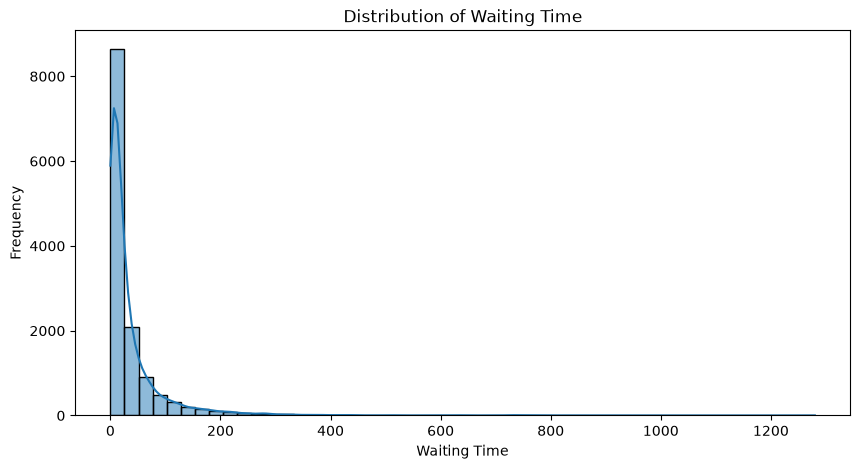

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["WAITTIME"],
    bins=50,
    kde=True
)

plt.title("Distribution of Waiting Time")
plt.xlabel("Waiting Time")
plt.ylabel("Frequency")

plt.show()

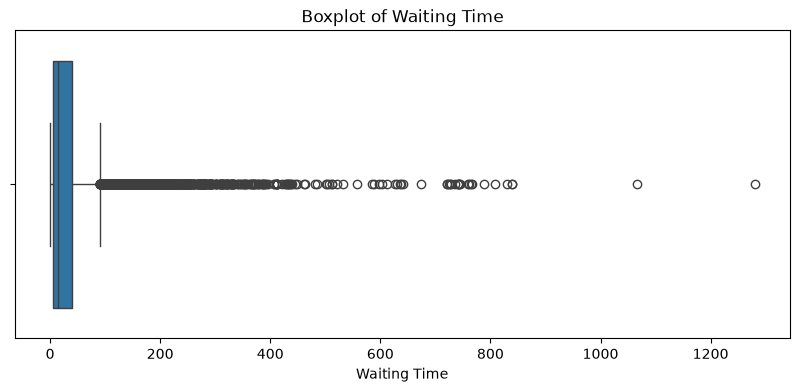

In [30]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_clean["WAITTIME"])

plt.title("Boxplot of Waiting Time")
plt.xlabel("Waiting Time")

plt.show()

In [31]:
Q1 = df_clean["WAITTIME"].quantile(0.25)
Q3 = df_clean["WAITTIME"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["WAITTIME"] < lower_limit) |
    (df_clean["WAITTIME"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))

Lower limit: -46.0
Upper limit: 90.0
Number of outliers: 1335


In [32]:
# Display the statistical summary of outliers

print(outliers["WAITTIME"].describe())

count    1335.000000
mean      183.721348
std       120.953652
min        91.000000
25%       112.000000
50%       145.000000
75%       207.000000
max      1280.000000
Name: WAITTIME, dtype: float64


In [33]:
print(
    df_clean["WAITTIME"]
    .sort_values(ascending=False)
    .head(20)
)

3885     1280
5077     1066
12776     839
10278     839
32        830
8577      808
10273     788
1121      767
3089      764
4879      761
5358      760
6300      745
6892      743
12797     743
4806      741
4783      741
8923      736
194       728
3203      727
3514      725
Name: WAITTIME, dtype: int64


In [34]:
print(
    "Waiting times above 90:",
    (df_clean["WAITTIME"] > 90).sum()
)

print(
    "Percentage:",
    round((df_clean["WAITTIME"] > 90).mean() * 100, 2),
    "%"
)

Waiting times above 90: 1335
Percentage: 10.06 %


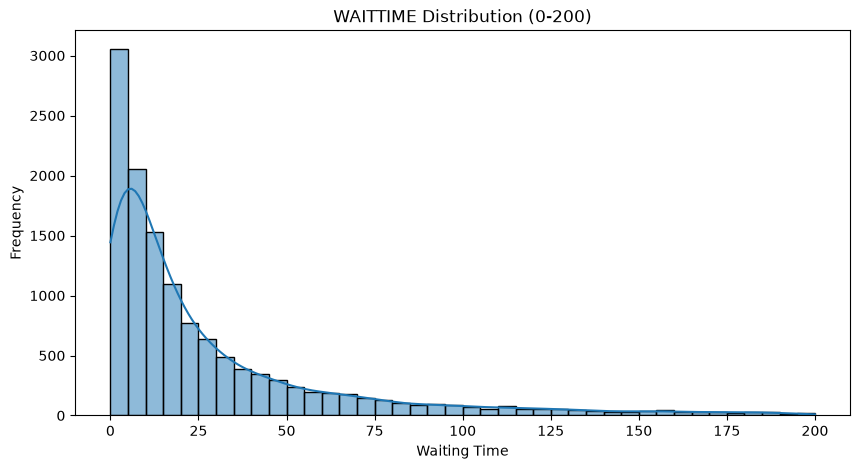

In [35]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean[df_clean["WAITTIME"] <= 200]["WAITTIME"],
    bins=40,
    kde=True
)

plt.title("WAITTIME Distribution (0-200)")
plt.xlabel("Waiting Time")
plt.ylabel("Frequency")

plt.show()

In [36]:
extreme_records = df_clean[
    df_clean["WAITTIME"] > 500
]

print("Number of extreme records:", len(extreme_records))

display(extreme_records.head(20))

Number of extreme records: 41


,VMONTH,VDAYR,ARRTIME,WAITTIME,LOV,AGE,AGER,AGEDAYS,RESIDNCE,SEX,...,RX30V3C2,RX30V3C3,RX30V3C4,SETTYPE,YEAR,CSTRATM,CPSUM,PATWT,EDWT,BOARDED
32,10,4,2,830,1032,66,5,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100001,3665.5696,NaN,-7
194,8,2,1033,728,-9,73,5,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100002,5554.7593,NaN,-9
1121,1,3,2223,767,2062,47,4,-7,3,2,...,NaN,NaN,NaN,3,2022,20122201,100011,2382.6729,NaN,-7
2003,12,3,1140,506,653,46,4,-7,1,1,...,NaN,NaN,NaN,3,2022,40100000,2,6383.8594,NaN,-7
2022,11,3,1003,627,954,69,5,-7,1,2,...,NaN,NaN,NaN,3,2022,40100000,2,12672.4660,NaN,15
2050,11,7,1354,513,1527,1,1,-7,1,2,...,NaN,NaN,NaN,3,2022,40100000,2,11535.6310,NaN,-7
2088,10,3,139,673,849,23,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100021,5554.7593,NaN,-7
2814,9,6,2134,635,780,42,3,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100028,6244.7620,NaN,-7
2840,9,5,1443,589,767,18,2,-7,1,1,...,NaN,NaN,NaN,3,2022,20122201,100028,6244.7620,NaN,-7
3089,2,4,2357,764,-9,28,3,-7,1,2,...,NaN,NaN,NaN,3,2022,20122201,100031,30867.1040,NaN,-7


In [42]:
import pandas as pd

stata_file = "dataset/raw/ed2022-stata.dta"

reader = pd.io.stata.StataReader(stata_file)

labels = reader.variable_labels()

for col in ["WAITTIME", "ARRTIME", "LOV", "AGE", "BOARDED"]:
    print(col, ":", labels.get(col))



WAITTIME : Wait time to first provider (Physician/APRN/PA) contact, in minutes
ARRTIME : Arrival time (military time)
LOV : Length of visit in minutes
AGE : Patient age in years
BOARDED : Length of time boarded in ED in minutes


In [43]:
print(
    df_clean.loc[
        df_clean["WAITTIME"] > 500,
        ["VMONTH", "VDAYR", "ARRTIME", "WAITTIME",
         "LOV", "AGE", "BOARDED"]
    ].head(10).to_string(index=False)
)

 VMONTH  VDAYR  ARRTIME  WAITTIME  LOV  AGE  BOARDED
     10      4        2       830 1032   66       -7
      8      2     1033       728   -9   73       -9
      1      3     2223       767 2062   47       -7
     12      3     1140       506  653   46       -7
     11      3     1003       627  954   69       15
     11      7     1354       513 1527    1       -7
     10      3      139       673  849   23       -7
      9      6     2134       635  780   42       -7
      9      5     1443       589  767   18       -7
      2      4     2357       764   -9   28       -7


In [44]:
reader = pd.io.stata.StataReader(
    "dataset/raw/ed2022-stata.dta"
)

labels = reader.variable_labels()

candidate_features = [
    "VMONTH",
    "VDAYR",
    "ARRTIME",
    "AGE",
    "AGER",
    "SEX",
    "ARREMS",
    "AMBTRANSFER",
    "RESIDNCE",
    "CATRIAGE",
    "WAITTIME",
    "LOV",
    "BOARDED"
]

for col in candidate_features:
    print(f"{col}: {labels.get(col, 'Label unavailable')}")

VMONTH: Month of Visit
VDAYR: Day of Week of Visit
ARRTIME: Arrival time (military time)
AGE: Patient age in years
AGER: Age recode
SEX: Patient sex
ARREMS: Arrival by ambulance
AMBTRANSFER: Was the patient transferred from another hospital or urgent care facility?
RESIDNCE: Patient residence
CATRIAGE: Does your ED use computer-assisted triage?
WAITTIME: Wait time to first provider (Physician/APRN/PA) contact, in minutes
LOV: Length of visit in minutes
BOARDED: Length of time boarded in ED in minutes


In [45]:
for col in candidate_features:
    if col in df_clean.columns:
        print(col, "Available")
    else:
        print(col, "Not found")

VMONTH Available
VDAYR Available
ARRTIME Available
AGE Available
AGER Available
SEX Available
ARREMS Available
AMBTRANSFER Available
RESIDNCE Available
CATRIAGE Available
WAITTIME Available
LOV Available
BOARDED Available


In [46]:
selected_features = [
    "VMONTH",
    "VDAYR",
    "ARRTIME",
    "AGE",
    "SEX",
    "ARREMS",
    "AMBTRANSFER",
    "RESIDNCE"
]

target = "WAITTIME"

df_model = df_clean[selected_features + [target]].copy()

print("Original cleaned dataset:", df_clean.shape)
print("Selected prediction dataset:", df_model.shape)

display(df_model.head())

Original cleaned dataset: (13272, 913)
Selected prediction dataset: (13272, 9)


,VMONTH,VDAYR,ARRTIME,AGE,SEX,ARREMS,AMBTRANSFER,RESIDNCE,WAITTIME
0,9,2,604,23,1,2,-7,1,10
1,9,2,1053,15,2,-9,-9,1,40
2,9,2,1419,19,2,2,-7,1,70
4,9,2,2243,18,1,2,-7,1,14
5,9,3,903,39,2,2,-7,1,2


In [47]:
print(df_model.isnull().sum())


VMONTH         0
VDAYR          0
ARRTIME        0
AGE            0
SEX            0
ARREMS         0
AMBTRANSFER    0
RESIDNCE       0
WAITTIME       0
dtype: int64


In [48]:
for col in selected_features:
    print("\n", col)
    print(df_model[col].value_counts(dropna=False).head(15))


 VMONTH
VMONTH
2     1341
12    1341
3     1196
7     1196
6     1173
11    1171
4     1137
8     1120
1     1058
10    1043
5      852
9      644
Name: count, dtype: int64

 VDAYR
VDAYR
2    2161
3    1987
4    1958
6    1890
5    1876
1    1715
7    1685
Name: count, dtype: int64

 ARRTIME
ARRTIME
1124    27
1309    23
1116    23
1835    22
1824    22
1530    22
1224    22
1052    22
1042    22
1312    21
1315    21
1630    21
1140    21
1212    21
1202    21
Name: count, dtype: int64

 AGE
AGE
0     335
1     270
2     229
19    214
31    212
30    211
34    195
29    194
3     193
25    191
26    188
61    185
18    184
56    184
21    183
Name: count, dtype: int64

 SEX
SEX
1    7065
2    6207
Name: count, dtype: int64

 ARREMS
ARREMS
 2    10607
 1     2391
-8      222
-9       52
Name: count, dtype: int64

 AMBTRANSFER
AMBTRANSFER
-7    10829
 2     1943
-9      227
-8      145
 1      128
Name: count, dtype: int64

 RESIDNCE
RESIDNCE
 1    12487
 2      257
 3      251
 4     

In [49]:
df_model_clean = df_model.copy()

print("Model dataset created successfully!")
print("Shape:", df_model_clean.shape)

Model dataset created successfully!
Shape: (13272, 9)


In [50]:
# ARREMS: -8 and -9 mean unknown
df_model_clean["ARREMS"] = df_model_clean["ARREMS"].replace({
    -8: "Unknown",
    -9: "Unknown"
})

# AMBTRANSFER: -7 means not applicable
df_model_clean["AMBTRANSFER"] = df_model_clean["AMBTRANSFER"].replace({
    -7: "Not applicable",
    -8: "Unknown",
    -9: "Unknown"
})

# RESIDNCE: -8 and -9 mean unknown
df_model_clean["RESIDNCE"] = df_model_clean["RESIDNCE"].replace({
    -8: "Unknown",
    -9: "Unknown"
})

print("Special codes replaced successfully!")

Special codes replaced successfully!


In [51]:
for col in ["ARREMS", "AMBTRANSFER", "RESIDNCE"]:
    print("\n", col)
    print(df_model_clean[col].value_counts())


 ARREMS
ARREMS
2          10607
1           2391
Unknown      274
Name: count, dtype: int64

 AMBTRANSFER
AMBTRANSFER
Not applicable    10829
2                  1943
Unknown             372
1                   128
Name: count, dtype: int64

 RESIDNCE
RESIDNCE
1          12487
2            257
3            251
4            146
Unknown      131
Name: count, dtype: int64


In [52]:
print("Dataset shape:", df_model_clean.shape)

print("\nMissing values:")
print(df_model_clean.isnull().sum())

print("\nData types:")
print(df_model_clean.dtypes)

Dataset shape: (13272, 9)

Missing values:
VMONTH         0
VDAYR          0
ARRTIME        0
AGE            0
SEX            0
ARREMS         0
AMBTRANSFER    0
RESIDNCE       0
WAITTIME       0
dtype: int64

Data types:
VMONTH          int64
VDAYR           int64
ARRTIME         int64
AGE             int64
SEX             int64
ARREMS         object
AMBTRANSFER    object
RESIDNCE       object
WAITTIME        int64
dtype: object


In [53]:
# Step 19: Check arrival time and age

print("Arrival time summary:")
print(df_model_clean["ARRTIME"].describe())

print("\nUnique arrival times (first 30):")
print(sorted(df_model_clean["ARRTIME"].unique())[:30])

print("\nAge summary:")
print(df_model_clean["AGE"].describe())

print("\nUnique sex values:")
print(df_model_clean["SEX"].value_counts())

print("\nMonth values:")
print(df_model_clean["VMONTH"].value_counts().sort_index())

print("\nDay of week values:")
print(df_model_clean["VDAYR"].value_counts().sort_index())

Arrival time summary:
count    13272.000000
mean      1345.883891
std        587.771032
min          0.000000
25%        953.000000
50%       1354.000000
75%       1819.000000
max       2359.000000
Name: ARRTIME, dtype: float64

Unique arrival times (first 30):
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]

Age summary:
count    13272.000000
mean        40.656947
std         25.064331
min          0.000000
25%         20.000000
50%         39.000000
75%         61.000000
max         94.000000
Name: AGE, dtype: float64

Unique sex values:
SEX
1    7065
2    6207
Name: count, dtype: int64

Month values:
VMONTH
1     1058
2     13

In [54]:
# Step 20: Convert arrival time into hour and minute

df_model_clean["ARR_HOUR"] = (
    df_model_clean["ARRTIME"] // 100
)

df_model_clean["ARR_MINUTE"] = (
    df_model_clean["ARRTIME"] % 100
)

# Convert arrival time into total minutes after midnight
df_model_clean["ARR_MINUTES"] = (
    df_model_clean["ARR_HOUR"] * 60
    + df_model_clean["ARR_MINUTE"]
)

print("Arrival time conversion completed!")

print(
    df_model_clean[
        ["ARRTIME", "ARR_HOUR", "ARR_MINUTE", "ARR_MINUTES"]
    ].head(10)
)

Arrival time conversion completed!
    ARRTIME  ARR_HOUR  ARR_MINUTE  ARR_MINUTES
0       604         6           4          364
1      1053        10          53          653
2      1419        14          19          859
4      2243        22          43         1363
5       903         9           3          543
6      1428        14          28          868
7      1830        18          30         1110
8       532         5          32          332
9      1638        16          38          998
10     2148        21          48         1308


In [55]:
print("Arrival hour range:")
print(
    df_model_clean["ARR_HOUR"].min(),
    "to",
    df_model_clean["ARR_HOUR"].max()
)

print("\nArrival minute range:")
print(
    df_model_clean["ARR_MINUTE"].min(),
    "to",
    df_model_clean["ARR_MINUTE"].max()
)

print("\nInvalid arrival times:")
print(
    df_model_clean[
        (df_model_clean["ARR_HOUR"] > 23) |
        (df_model_clean["ARR_MINUTE"] > 59)
    ].shape[0]
)

Arrival hour range:
0 to 23

Arrival minute range:
0 to 59

Invalid arrival times:
0


In [56]:
# Step 21: Remove redundant arrival-time columns

df_model_clean = df_model_clean.drop(
    columns=["ARRTIME", "ARR_HOUR", "ARR_MINUTE"]
)

print("Redundant columns removed!")

print("\nDataset shape:")
print(df_model_clean.shape)

print("\nRemaining columns:")
print(df_model_clean.columns.tolist())

print("\nFirst 5 rows:")
display(df_model_clean.head())

Redundant columns removed!

Dataset shape:
(13272, 9)

Remaining columns:
['VMONTH', 'VDAYR', 'AGE', 'SEX', 'ARREMS', 'AMBTRANSFER', 'RESIDNCE', 'WAITTIME', 'ARR_MINUTES']

First 5 rows:


,VMONTH,VDAYR,AGE,SEX,ARREMS,AMBTRANSFER,RESIDNCE,WAITTIME,ARR_MINUTES
0,9,2,23,1,2,Not applicable,1,10,364
1,9,2,15,2,Unknown,Unknown,1,40,653
2,9,2,19,2,2,Not applicable,1,70,859
4,9,2,18,1,2,Not applicable,1,14,1363
5,9,3,39,2,2,Not applicable,1,2,543


In [57]:
# Step 22: Separate features and target

X = df_model_clean.drop(columns=["WAITTIME"])
y = df_model_clean["WAITTIME"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (13272, 8)
Target shape: (13272,)

Feature columns:
['VMONTH', 'VDAYR', 'AGE', 'SEX', 'ARREMS', 'AMBTRANSFER', 'RESIDNCE', 'ARR_MINUTES']


In [58]:
# Step 23: Identify numerical and categorical columns

categorical_features = [
    "VMONTH",
    "VDAYR",
    "SEX",
    "ARREMS",
    "AMBTRANSFER",
    "RESIDNCE"
]

numerical_features = [
    "AGE",
    "ARR_MINUTES"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)


Categorical features:
['VMONTH', 'VDAYR', 'SEX', 'ARREMS', 'AMBTRANSFER', 'RESIDNCE']

Numerical features:
['AGE', 'ARR_MINUTES']


In [59]:
# Step 24: Train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (10617, 8)
Testing features: (2655, 8)
Training target: (10617,)
Testing target: (2655,)


In [60]:
# Step 25: Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [61]:
# Step 26: Create preprocessing pipeline

# Process numerical features
numerical_transformer = StandardScaler()

# Process categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [65]:
# Step 29: Apply preprocessing again

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nTraining data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Preprocessing completed successfully!

Training data shape: (10617, 35)
Testing data shape: (2655, 35)


In [64]:
# Step 28: Convert categorical columns to string

X_train[categorical_features] = (
    X_train[categorical_features].astype(str)
)

X_test[categorical_features] = (
    X_test[categorical_features].astype(str)
)

print("Categorical columns converted to strings!")

print("\nTraining data types:")
print(X_train[categorical_features].dtypes)

print("\nTesting data types:")
print(X_test[categorical_features].dtypes)

Categorical columns converted to strings!

Training data types:
VMONTH         str
VDAYR          str
SEX            str
ARREMS         str
AMBTRANSFER    str
RESIDNCE       str
dtype: object

Testing data types:
VMONTH         str
VDAYR          str
SEX            str
ARREMS         str
AMBTRANSFER    str
RESIDNCE       str
dtype: object


In [66]:
# Step 30: Import Linear Regression and evaluation metrics

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Linear Regression libraries imported successfully!")

Linear Regression libraries imported successfully!


In [67]:
# Step 31: Train Linear Regression model

lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [68]:
# Step 32: Predict waiting times

y_pred_lr = lr_model.predict(X_test_processed)

print("Predictions completed!")

print("\nFirst 10 actual waiting times:")
print(y_test.head(10).values)

print("\nFirst 10 predicted waiting times:")
print(y_pred_lr[:10])

Predictions completed!

First 10 actual waiting times:
[ 7 19 12 11 13 79 22 15  2 14]

First 10 predicted waiting times:
[22.27258203 37.53335372 27.38474847 31.74052142 31.49204774 47.06584544
 32.33816792 47.67681269 48.41188866 49.35580757]


In [69]:
# Step 33: Evaluate Linear Regression model

mae_lr = mean_absolute_error(y_test, y_pred_lr)

mse_lr = mean_squared_error(y_test, y_pred_lr)

rmse_lr = mse_lr ** 0.5

r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression Results
--------------------------
MAE: 33.6557812178503
MSE: 3966.9831900555387
RMSE: 62.983991537973665
R2 Score: 0.033555210737863383


In [70]:
# Step 35: Import Random Forest

from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [71]:
# Step 36: Train Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [72]:
# Step 37: Random Forest predictions

y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10])

Random Forest predictions completed!

First 10 actual values:
[ 7 19 12 11 13 79 22 15  2 14]

First 10 predicted values:
[29.78       24.99       31.24       11.59       11.56       65.6
 23.12       31.34333333 68.12       75.19      ]


In [73]:
# Step 38: Evaluate Random Forest

mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = mse_rf ** 0.5

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
---------------------
MAE: 37.24404176307058
MSE: 4454.107779669742
RMSE: 66.73910232891765
R2 Score: -0.08511910644458776


In [74]:
# Step 40: Import Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor

print("Gradient Boosting imported successfully!")

Gradient Boosting imported successfully!


In [75]:
# Step 41: Train Gradient Boosting model

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [76]:
# Step 42: Gradient Boosting predictions

y_pred_gb = gb_model.predict(X_test_processed)

print("Gradient Boosting predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_gb[:10])

Gradient Boosting predictions completed!

First 10 actual values:
[ 7 19 12 11 13 79 22 15  2 14]

First 10 predicted values:
[25.35335421 40.23812308 30.84803332 32.64961829 26.48296453 51.02370711
 27.5399212  41.45986929 47.23463119 58.85749608]


In [77]:
# Step 43: Evaluate Gradient Boosting

mae_gb = mean_absolute_error(y_test, y_pred_gb)

mse_gb = mean_squared_error(y_test, y_pred_gb)

rmse_gb = mse_gb ** 0.5

r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Results
-------------------------
MAE: 34.04998797392161
MSE: 3959.4461476321767
RMSE: 62.92413009038883
R2 Score: 0.03539140086711989


In [78]:
# Step 44: Compare all three models

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_lr,
        mae_rf,
        mae_gb
    ],
    "MSE": [
        mse_lr,
        mse_rf,
        mse_gb
    ],
    "RMSE": [
        rmse_lr,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_lr,
        r2_rf,
        r2_gb
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,33.6558,3966.9832,62.9840,0.0336
1,Random Forest,37.2440,4454.1078,66.7391,-0.0851
2,Gradient Boosting,34.0500,3959.4461,62.9241,0.0354


In [79]:
# Step 45: Identify the best model

best_model = results.loc[
    results["R2 Score"].idxmax()
]

print("Best Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

Best Model: Gradient Boosting
MAE: 34.04998797392161
RMSE: 62.92413009038883
R2 Score: 0.03539140086711989


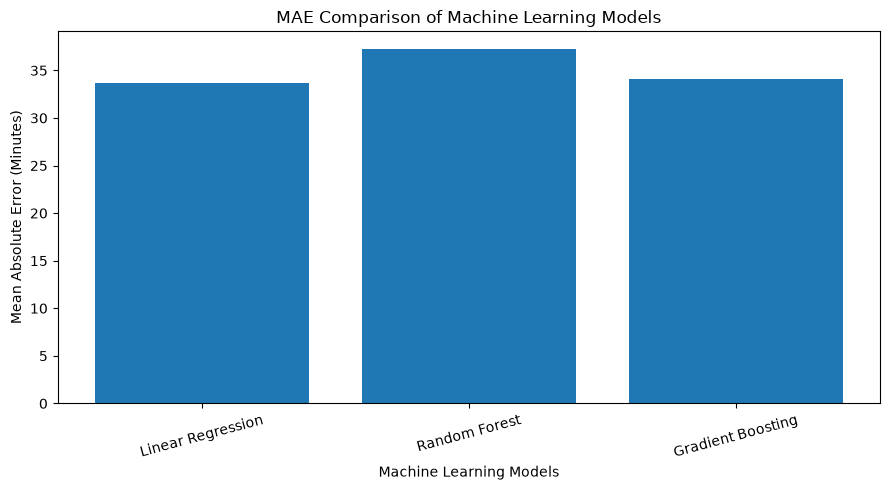

In [80]:
# Step 46: Visualize model performance

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(results["Model"], results["MAE"])

plt.title("MAE Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error (Minutes)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

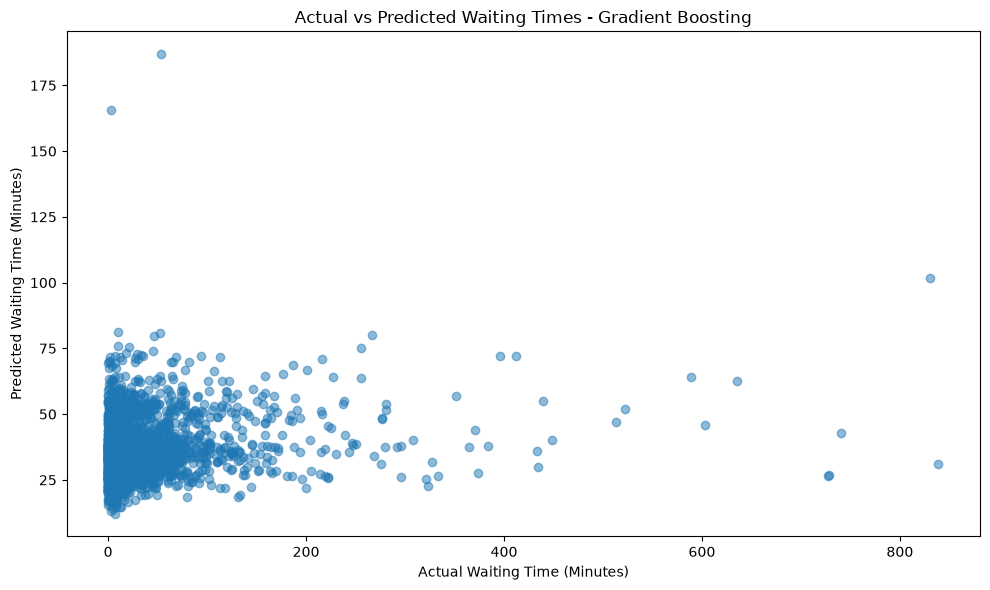

In [81]:
# Step 47: Actual vs Predicted Waiting Times

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred_gb,
    alpha=0.5
)

plt.xlabel("Actual Waiting Time (Minutes)")
plt.ylabel("Predicted Waiting Time (Minutes)")

plt.title("Actual vs Predicted Waiting Times - Gradient Boosting")

plt.tight_layout()
plt.show()

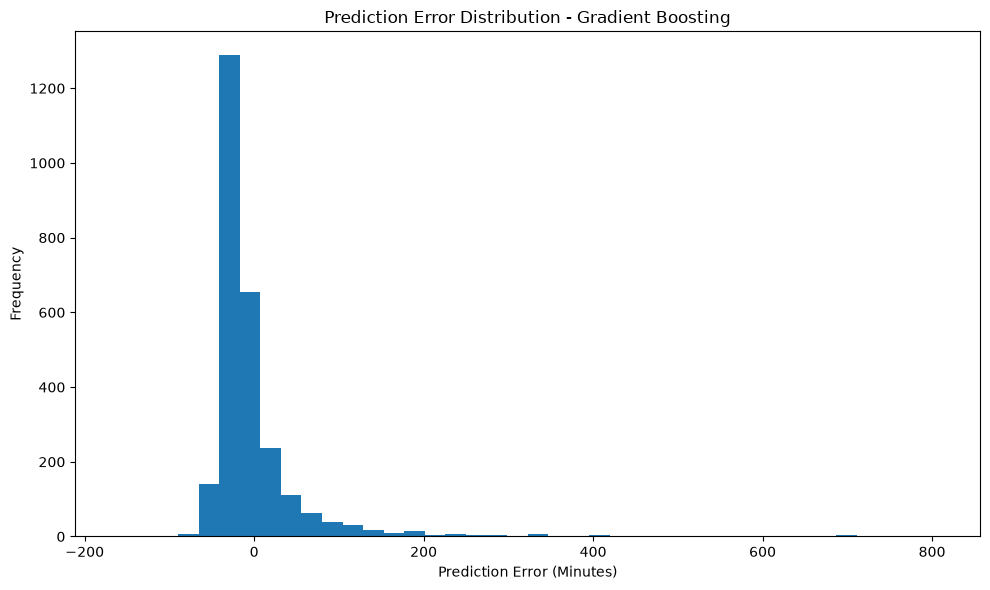

In [82]:
# Step 48: Prediction Error Distribution

errors = y_test - y_pred_gb

plt.figure(figsize=(10, 6))

plt.hist(errors, bins=40)

plt.xlabel("Prediction Error (Minutes)")
plt.ylabel("Frequency")

plt.title("Prediction Error Distribution - Gradient Boosting")

plt.tight_layout()
plt.show()

In [83]:
# Step 49: Feature Importance

feature_names = preprocessor.get_feature_names_out()

importance = gb_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")

display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
1,num__ARR_MINUTES,0.346326
13,cat__VMONTH_9,0.120167
0,num__AGE,0.081986
5,cat__VMONTH_12,0.070015
3,cat__VMONTH_10,0.068050
27,cat__AMBTRANSFER_2,0.040269
4,cat__VMONTH_11,0.038200
23,cat__ARREMS_1,0.036430
7,cat__VMONTH_3,0.027857
24,cat__ARREMS_2,0.018233


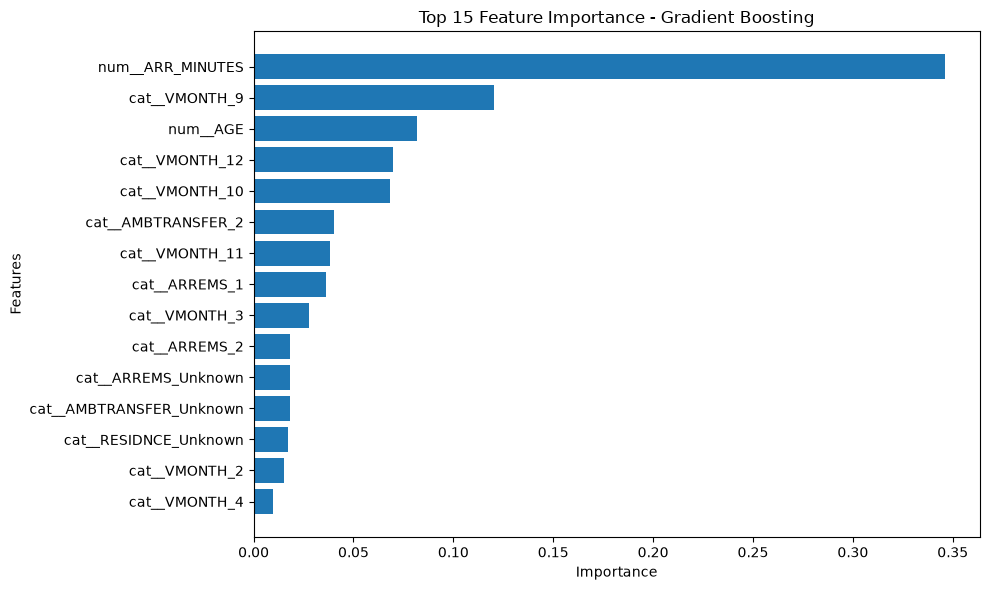

In [84]:
# Step 49.1: Plot Feature Importance

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Feature Importance - Gradient Boosting")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Feature Importance Analysis

The Gradient Boosting model's feature importance analysis identified arrival time as the most influential feature, with an importance score of approximately 0.3463.

Other important features included the month of hospital visit, patient age, ambulance arrival status, and hospital transfer status.

The results suggest that the time of arrival and seasonal patterns may provide useful information for predicting emergency department waiting times.

However, the model's overall R² score is approximately 0.0354, indicating that the selected features explain only a small proportion of the variation in waiting times. Therefore, the feature importance results should be interpreted cautiously.

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(gb_model, "../models/gradient_boosting_model.pkl")

joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model and preprocessing pipeline saved successfully!")

In [85]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(gb_model, "../models/gradient_boosting_model.pkl")

joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model and preprocessing pipeline saved successfully!")

Model and preprocessing pipeline saved successfully!


In [86]:
import os

os.makedirs("../results", exist_ok=True)

results.to_csv("../results/model_comparison.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [87]:
feature_importance.to_csv(
    "../results/feature_importance.csv",
    index=False
)

print("Feature importance results saved successfully!")

Feature importance results saved successfully!


In [88]:
import os

for folder in ["../models", "../results"]:
    print(f"\n{folder}")
    for file in os.listdir(folder):
        print(" -", file)


../models
 - gradient_boosting_model.pkl
 - preprocessor.pkl

../results
 - model_comparison.csv
 - feature_importance.csv
